# Прогнозирование отмены бронирования в сети отелей UrbanStay

**Автор:** Куницын Денис

**Дата:** 20 мая

## Цель и задачи

**Бизнес-задача:** снизить финансовые потери сети отелей за счёт раннего выявления бронирований с высоким риском отмены и сохранения приемлемой загрузки номерного фонда.

**Цель в терминах Machine Learning:** построить модель бинарной классификации, которая по данным о бронировании и предыдущих отзывах гостей оценивает вероятность отмены брони.

**Задачи:**

1. Загрузить данные из PostgreSQL с помощью SQLAlchemy и проверить качество исходных таблиц `hotel_bookings` и `hotel_reviews`.
2. Провести исследовательский анализ данных, выявить пропуски, дубликаты и аномалии, а также проанализировать распределения ключевых признаков.
3. Объединить бронирования и отзывы по правилу ближайшего предыдущего отзыва относительно даты бронирования.
4. Создать признаки на основе параметров бронирования и текстов отзывов, включая векторизацию текста.
5. Обучить и сравнить несколько моделей, откалибровать лучшую модель и подобрать оптимальный порог классификации по метрике Incremental Revenue.
6. Оценить экономическую эффективность модели, сравнить матрицы ошибок и сделать итоговые выводы для бизнеса.

## Данные

В проекте используются две таблицы из PostgreSQL: `hotel_bookings` с параметрами бронирований и `hotel_reviews` с историей отзывов гостей. Таблицы соединяются по идентификатору клиента и правилу ближайшего предыдущего отзыва, чтобы связать обратную связь с конкретным периодом проживания.

### Описание датасетов

1. `hotel_bookings`

Таблица бронирований, по которой формируется целевая переменная и основная часть признаков.

- `booking_id` — идентификатор бронирования.
- `booking_date` — дата бронирования.
- `booking_status` — статус бронирования, на его основе формируется целевой признак `is_cancelled`.
- `adult_count`, `child_count` — состав гостей.
- `previous_cancellations`, `previous_no_shows` — история отмен и незаездов.
- `booking_value` — стоимость бронирования.
- `days_until_checkin` — число дней до заезда.
- `weekday_nights`, `weekend_nights` — число ночей по будням и выходным.
- `customer_special_requests` — число специальных запросов клиента.
- `sales_channel`, `meal_plan`, `parking_included`, `room_type`, `returning_customer` — категориальные признаки бронирования.

2. `hotel_reviews`

Таблица отзывов гостей, из которой берутся текст комментария и оценка проживания.

- `booking_id` — идентификатор бронирования.
- `customer_id` — идентификатор клиента.
- `review_date` — дата отзыва.
- `stay_rating` — оценка проживания.
- `review_text` — текст отзыва, используемый для построения TF-IDF признаков.

## Структура проекта

1. Подготовка данных
2. Моделирование
3. Расчет экономической эффективности модели 
4. Выводы по проекту

---

## Загрузка необходимых библиотек

In [1]:
requirements_txt = """pandas==2.2.3
numpy==1.26.4
matplotlib==3.9.4
phik==0.12.5
shap==0.47.0
seaborn==0.13.2
scikit-learn==1.6.1
lightgbm==4.5.0
catboost==1.2.8
xgboost==3.1.0
optuna==4.8.0
dotenv==0.9.9
joblib==1.4.2
SQLAlchemy==2.0.49
"""

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_txt)

!pip -q install -r requirements.txt

zsh:1: command not found: pip


In [2]:
from __future__ import annotations

import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import seaborn as sns
from catboost import CatBoostClassifier
from dotenv import load_dotenv
from lightgbm import LGBMClassifier
from phik import phik_matrix
from scipy import sparse
from sqlalchemy import create_engine
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV, FrozenEstimator
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', message='X does not have valid feature names*')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)

RANDOM_STATE = 42
TRAIN_RATIO = 0.6
CALIB_RATIO = 0.2
TEST_RATIO = 0.2
IR_AVG_REV = 64500
IR_COST_FP = 7000
IR_LOST_REV = 64500
IR_PER_REBOOKING = 45000
DB_ENV_PATH = Path('.env')


def format_money(value: float) -> str:
    return f"{value:,.0f} ₽".replace(',', ' ')


def format_money_millions(value: float) -> str:
    return f"{value / 1_000_000:.1f} млн ₽"


def format_percent(value: float) -> str:
    return f"{value:.2f}%"


def format_fraction_as_percent(value: float) -> str:
    return f"{value * 100:.2f}%"

---

## Этап 1: подготовка данных

### 1.1 Загрузка данных

In [3]:
load_dotenv(DB_ENV_PATH)

db_host = os.getenv('HOTEL_DB_HOST')
db_name = os.getenv('HOTEL_DB_NAME')
db_port = os.getenv('HOTEL_DB_PORT')
db_user = os.getenv('HOTEL_DB_USER')
db_password = os.getenv('HOTEL_DB_PASSWORD')

required_env = {
    'HOTEL_DB_HOST': db_host,
    'HOTEL_DB_NAME': db_name,
    'HOTEL_DB_PORT': db_port,
    'HOTEL_DB_USER': db_user,
    'HOTEL_DB_PASSWORD': db_password,
}

missing_env = [name for name, value in required_env.items() if not value]
if missing_env:
    raise ValueError(f'Не заданы переменные окружения: {missing_env}')

engine = create_engine(
    f'postgresql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}'
)

query_bookings = 'SELECT * FROM hotel_bookings'
query_reviews = 'SELECT * FROM hotel_reviews'

df_bookings = pd.read_sql_query(query_bookings, engine)
df_reviews = pd.read_sql_query(query_reviews, engine)

print('Загрузка данных завершена')
print(f'Бронирования: {df_bookings.shape[0]:,} строк × {df_bookings.shape[1]:,} столбцов')
print(f'Отзывы: {df_reviews.shape[0]:,} строк × {df_reviews.shape[1]:,} столбцов')

display(df_bookings.head())
display(df_reviews.head())

print('\nТипы данных в bookings:')
display(df_bookings.dtypes.to_frame('dtype'))
print('\nТипы данных в reviews:')
display(df_reviews.dtypes.to_frame('dtype'))

Загрузка данных завершена
Бронирования: 35,341 строк × 17 столбцов
Отзывы: 25,177 строк × 5 столбцов


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни..."
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...



Типы данных в bookings:


,dtype
booking_id,object
booking_date,object
sales_channel,object
adult_count,int64
child_count,int64
returning_customer,bool
previous_cancellations,int64
previous_no_shows,int64
booking_status,object
booking_value,float64



Типы данных в reviews:


,dtype
customer_id,object
booking_id,object
review_date,object
stay_rating,int64
review_text,object


### 1.2 Исследовательский анализ данных и предобработка

Размер bookings: (35341, 18)
Размер reviews: (25177, 6)


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,is_cancelled
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1,0
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1,0


,customer_id,booking_id,review_date,stay_rating,review_text,review_length
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в...",97
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не...",62
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...,71
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни...",104
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...,86



bookings: пропуски и кардинальность


,missing_count,missing_share
booking_id,0,0.0
booking_date,0,0.0
customer_special_requests,0,0.0
room_type,0,0.0
parking_included,0,0.0
meal_plan,0,0.0
weekend_nights,0,0.0
weekday_nights,0,0.0
days_until_checkin,0,0.0
booking_value,0,0.0


Дубликаты строк в bookings: 4,608

reviews: пропуски и кардинальность


... (3 outputs left out)


Числовые признаки bookings:


,count,mean,std,min,25%,50%,75%,max
adult_count,35341.0,12.479726,45.726290,1.0,1.0,2.0,3.0,300.0
child_count,35341.0,0.358988,0.587324,0.0,0.0,0.0,1.0,2.0
previous_cancellations,35341.0,0.356923,0.628771,0.0,0.0,0.0,1.0,5.0
previous_no_shows,35341.0,0.839535,0.931724,0.0,0.0,1.0,1.0,5.0
booking_value,35341.0,61634.055219,42837.589968,0.0,33500.0,53600.0,80400.0,417221.2
days_until_checkin,35341.0,100.523726,71.872677,2.0,45.0,90.0,144.0,300.0
weekday_nights,35341.0,6.532922,3.339492,1.0,5.0,6.0,9.0,15.0
weekend_nights,35341.0,1.953991,1.477249,0.0,0.0,2.0,2.0,6.0
customer_special_requests,35341.0,0.621488,0.784391,0.0,0.0,0.0,1.0,5.0
is_cancelled,35341.0,0.287598,0.452649,0.0,0.0,0.0,1.0,1.0



Числовые признаки reviews:


,count,mean,std,min,25%,50%,75%,max
stay_rating,25177.0,3.395321,0.541434,2.0,3.0,3.0,4.0,5.0
review_length,25177.0,92.350637,32.189530,26.0,65.0,95.0,113.0,225.0


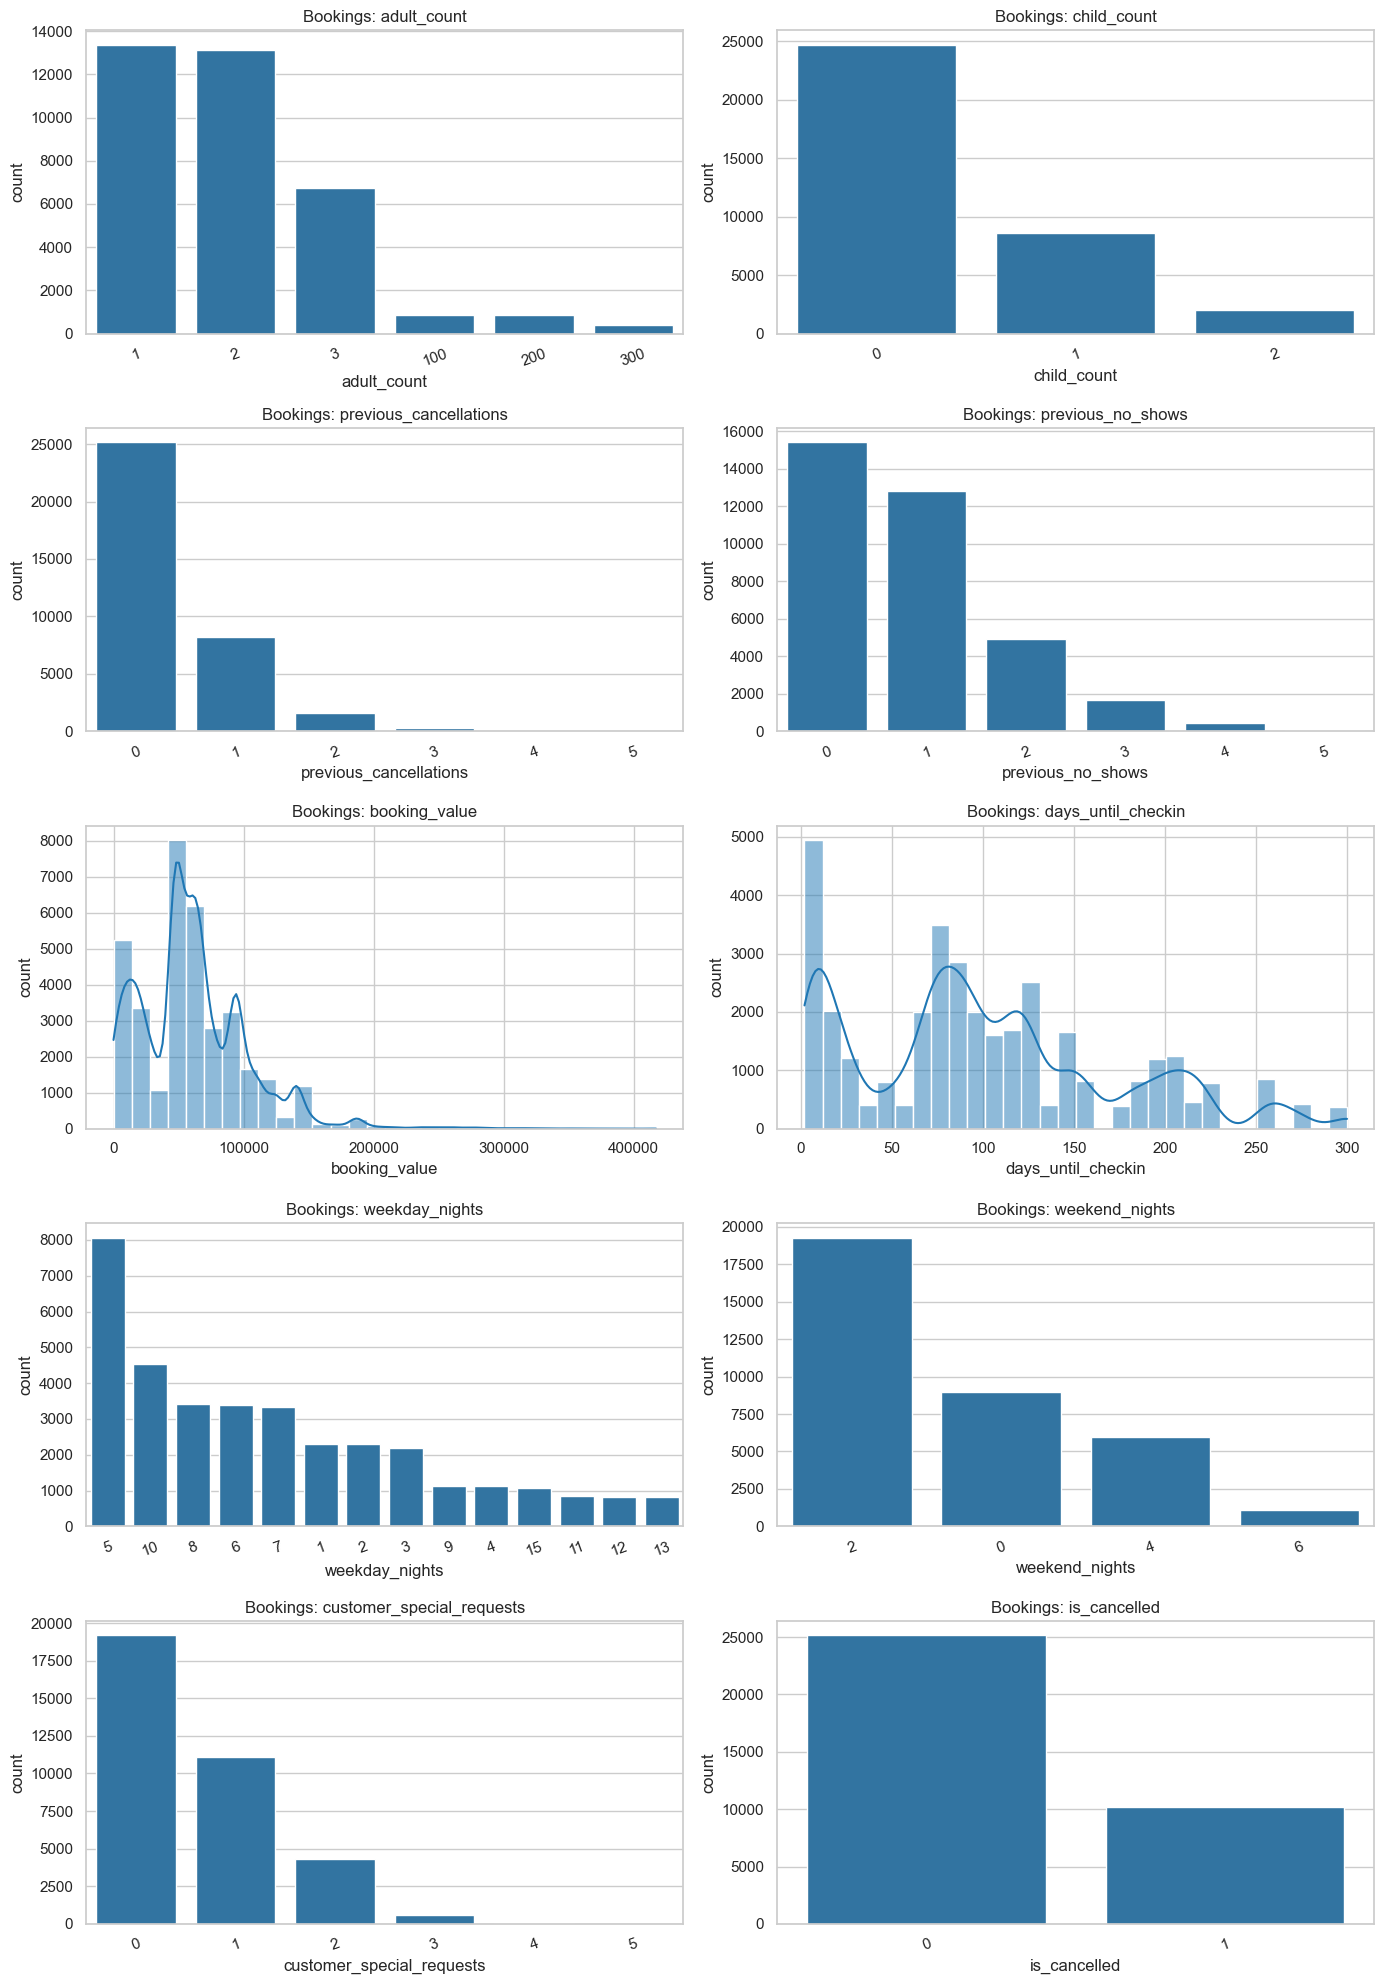

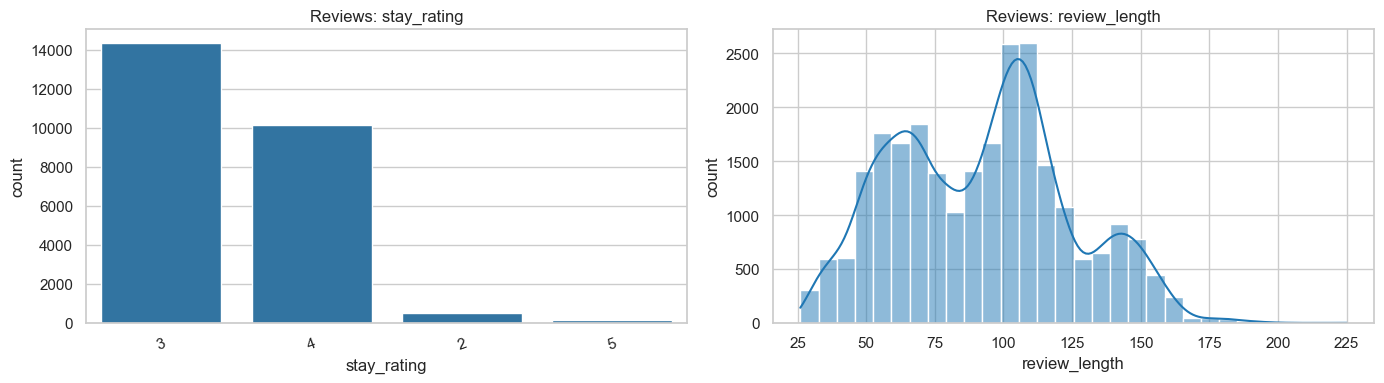

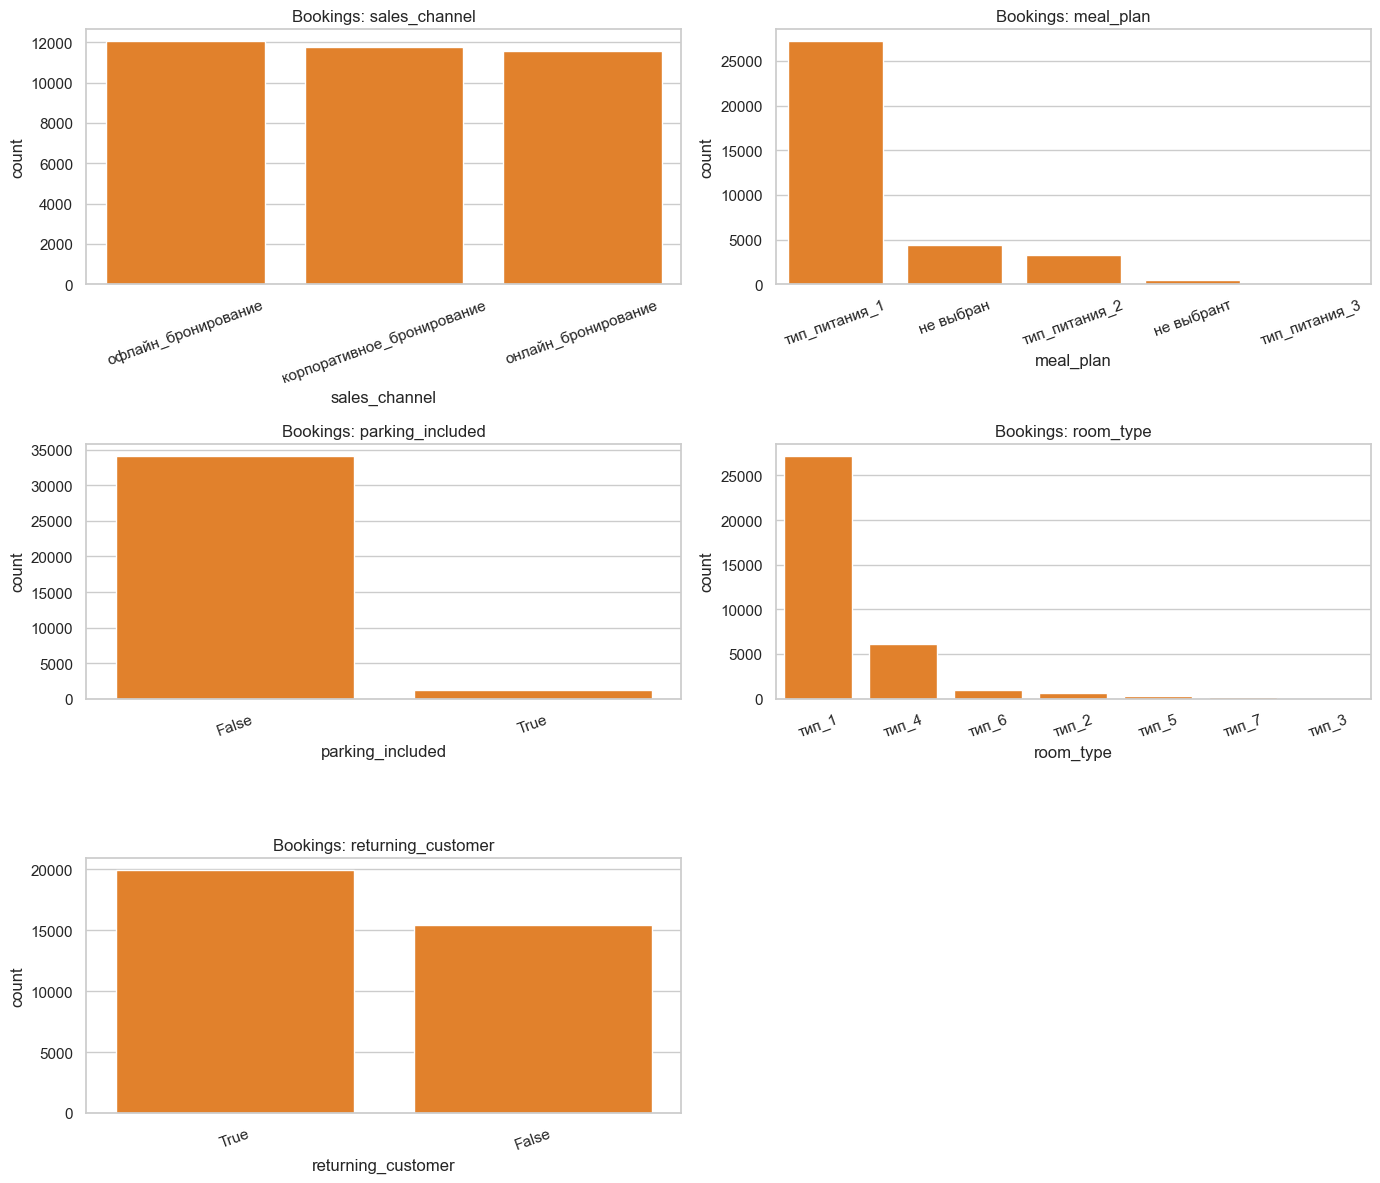

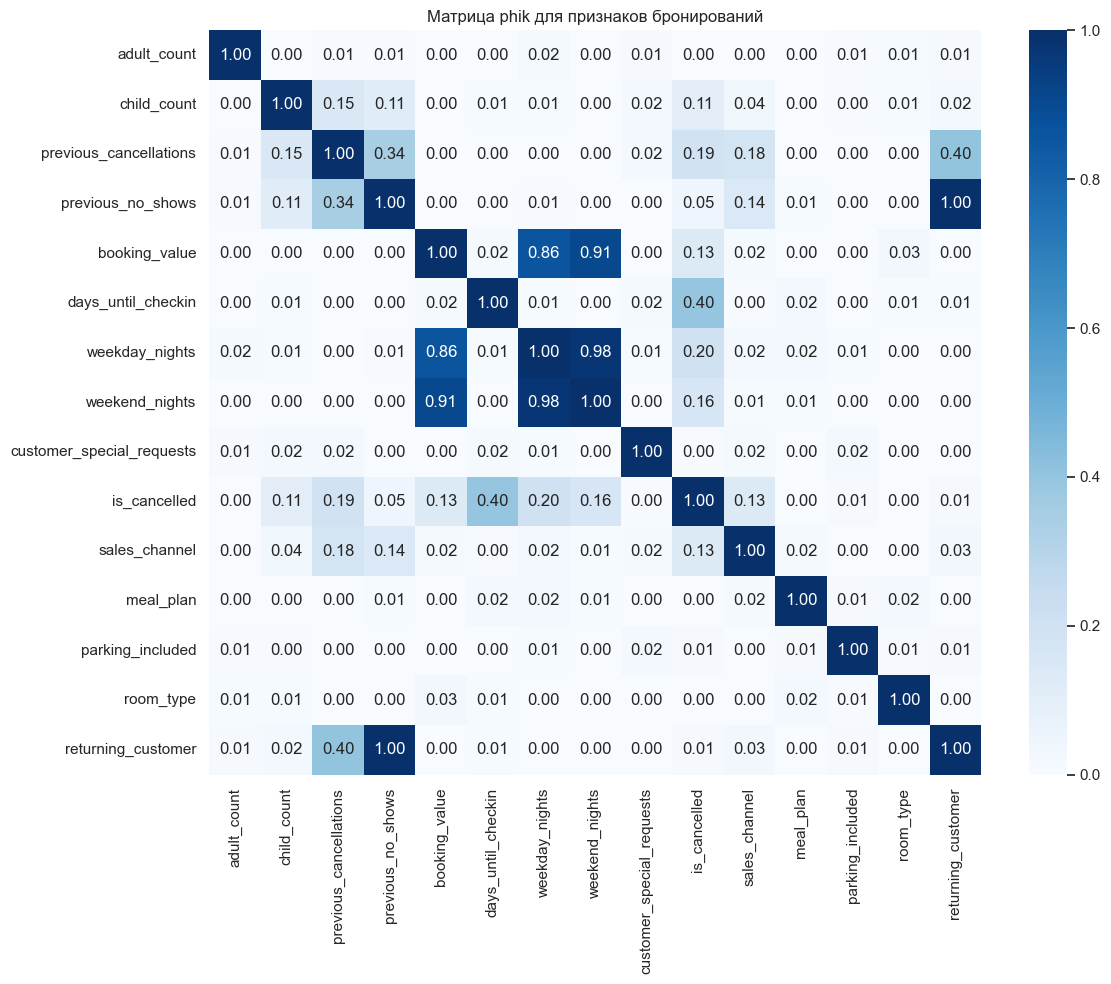


Квантили длины отзывов: {0.5: 95.0, 0.9: 139.0, 0.95: 149.0}


In [4]:
bookings_eda = df_bookings.copy()
reviews_eda = df_reviews.copy()

bookings_eda['booking_date'] = pd.to_datetime(bookings_eda['booking_date'], errors='coerce')
reviews_eda['review_date'] = pd.to_datetime(reviews_eda['review_date'], errors='coerce')
bookings_eda['is_cancelled'] = (bookings_eda['booking_status'] == 'отказ_брони').astype(int)
reviews_eda['review_length'] = reviews_eda['review_text'].astype(str).str.len()


def describe_missing(df: pd.DataFrame, name: str) -> pd.DataFrame:
    summary = (
        df.isna()
        .sum()
        .rename('missing_count')
        .to_frame()
        .assign(missing_share=lambda x: (x['missing_count'] / len(df) * 100).round(2))
        .sort_values('missing_count', ascending=False)
    )
    print(f'\n{name}: пропуски и кардинальность')
    display(summary)
    print(f'Дубликаты строк в {name}: {df.duplicated().sum():,}')
    return summary


def plot_numeric_eda(df: pd.DataFrame, numeric_cols: list[str], title: str) -> None:
    if not numeric_cols:
        return
    ncols = 2
    nrows = int(np.ceil(len(numeric_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, numeric_cols):
        unique_count = df[col].nunique(dropna=True)
        if unique_count < 15:
            order = df[col].dropna().astype(str).value_counts().index
            sns.countplot(data=df, x=col, order=order, ax=ax, color='#1f77b4')
            ax.set_ylabel('count')
            ax.tick_params(axis='x', rotation=20)
        else:
            sns.histplot(df[col].dropna(), kde=True, bins=30, ax=ax, color='#1f77b4')
            ax.set_ylabel('count')
        ax.set_title(f'{title}: {col}')
        ax.set_xlabel(col)
    for ax in axes[len(numeric_cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def plot_categorical_eda(df: pd.DataFrame, cat_cols: list[str], title: str) -> None:
    if not cat_cols:
        return
    ncols = 2
    nrows = int(np.ceil(len(cat_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cat_cols):
        order = df[col].astype(str).value_counts().index
        sns.countplot(data=df, x=col, order=order, ax=ax, color='#ff7f0e')
        ax.set_title(f'{title}: {col}')
        ax.tick_params(axis='x', rotation=20)
    for ax in axes[len(cat_cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


print('Размер bookings:', bookings_eda.shape)
print('Размер reviews:', reviews_eda.shape)

display(bookings_eda.head())
display(reviews_eda.head())

describe_missing(bookings_eda, 'bookings')
describe_missing(reviews_eda, 'reviews')

print('\nДиапазон booking_date:', bookings_eda['booking_date'].min(), '-', bookings_eda['booking_date'].max())
print('Диапазон review_date:', reviews_eda['review_date'].min(), '-', reviews_eda['review_date'].max())

print('\nРаспределение booking_status:')
display(bookings_eda['booking_status'].value_counts().to_frame('count').assign(share=lambda x: (x['count'] / len(bookings_eda) * 100).round(2)))

numeric_booking_cols = [
    'adult_count',
    'child_count',
    'previous_cancellations',
    'previous_no_shows',
    'booking_value',
    'days_until_checkin',
    'weekday_nights',
    'weekend_nights',
    'customer_special_requests',
    'is_cancelled',
]

categorical_booking_cols = [
    'sales_channel',
    'meal_plan',
    'parking_included',
    'room_type',
    'returning_customer',
]

numeric_review_cols = ['stay_rating', 'review_length']

print('\nЧисловые признаки bookings:')
display(bookings_eda[numeric_booking_cols].describe().T)

print('\nЧисловые признаки reviews:')
display(reviews_eda[numeric_review_cols].describe().T)

plot_numeric_eda(bookings_eda, numeric_booking_cols, 'Bookings')
plot_numeric_eda(reviews_eda, numeric_review_cols, 'Reviews')

plot_categorical_eda(bookings_eda, categorical_booking_cols, 'Bookings')

phik_cols = numeric_booking_cols + categorical_booking_cols
phik_data = bookings_eda[phik_cols].copy()
phik_matrix_values = phik_matrix(phik_data, interval_cols=[col for col in numeric_booking_cols if col != 'is_cancelled'])
plt.figure(figsize=(12, 10))
sns.heatmap(phik_matrix_values, annot=True, cmap='Blues', fmt='.2f', vmin=0, vmax=1)
plt.title('Матрица phik для признаков бронирований')
plt.tight_layout()
plt.show()

booking_corr_cols = [col for col in numeric_booking_cols if col in bookings_eda.columns]

# Для интерпретации частотных значений и хвостов сохраняем сводку квантилей по длине текста.
top_text_lengths = reviews_eda['review_length'].quantile([0.5, 0.9, 0.95]).to_dict()
print('\nКвантили длины отзывов:', top_text_lengths)

#### Выводы по исследовательскому анализу данных

- В обеих исходных таблицах пропуски отсутствуют, поэтому базовая очистка будет сосредоточена на типах данных, дубликатах и аномальных значениях.
- В таблице бронирований обнаружено 4 608 полных дубликатов строк, которые нужно учитывать на этапе предобработки.
- Признак `booking_status` имеет две категории: `нет_отказа` и `отказ_брони`; целевую переменную для моделирования можно сформировать на его основе.
- Для числовых признаков с низкой кардинальностью использованы столбчатые диаграммы, а для непрерывных признаков — гистограммы. Это делает распределения дискретных счётчиков и дат более читаемыми.
- Для смешанных признаков построена матрица `phik`, а не только корреляция Пирсона; она позволяет видеть связи категориальных и числовых признаков в одной шкале.
- В числовых признаках бронирований заметны сильные асимметрии и выбросы: особенно выделяется `adult_count` со значением до 300, что требует дополнительной проверки и обработки.
- Признаки `booking_value`, `days_until_checkin`, `weekday_nights` и `weekend_nights` также имеют выраженную правостороннюю асимметрию, поэтому для них потребуется аккуратная обработка выбросов и, вероятно, масштабирование.
- Категориальные признаки распределены неравномерно: доминируют `тип_питания_1`, `тип_1` в `room_type`, а также высокий вклад онлайн и корпоративных каналов бронирования.
- В таблице отзывов наблюдается умеренно различающаяся длина текста и сосредоточенные оценки `stay_rating` в диапазоне 3–4, что полезно для текстовых признаков и анализа качества обслуживания.

---

### 1.3 Предобработка данных

In [5]:
def _fix_adult(x):
    try:
        x = int(x)
    except Exception:
        return x
    if x < 10:
        return x
    if x % 10 == 0:
        while x >= 10:
            x //= 10
        return x
    return np.nan


def prepare_source_tables(bookings: pd.DataFrame, reviews: pd.DataFrame):
    bookings = bookings.copy()
    reviews = reviews.copy()

    bookings['booking_date'] = pd.to_datetime(bookings['booking_date'], errors='coerce')
    reviews['review_date'] = pd.to_datetime(reviews['review_date'], errors='coerce')

    bookings = bookings.drop_duplicates().reset_index(drop=True)

    bookings['booking_value'] = bookings[bookings['booking_value'] > 0]['booking_value']

    bookings.loc[bookings['meal_plan'] == 'не выбрант', 'meal_plan'] = 'не выбран'

    # Обработка аномалий adult_count: все значения >10 считаем ошибочными
    bookings['adult_count'] = bookings['adult_count'].apply(_fix_adult).astype(float).clip(upper=10)
    bookings['child_count'] = bookings['child_count'].clip(lower=0, upper=5)
    bookings['previous_cancellations'] = bookings['previous_cancellations'].clip(lower=0, upper=5)
    bookings['previous_no_shows'] = bookings['previous_no_shows'].clip(lower=0, upper=5)
    bookings['days_until_checkin'] = bookings['days_until_checkin'].clip(lower=0, upper=365)
    bookings['weekday_nights'] = bookings['weekday_nights'].clip(lower=0, upper=14)
    bookings['weekend_nights'] = bookings['weekend_nights'].clip(lower=0, upper=7)
    bookings['customer_special_requests'] = bookings['customer_special_requests'].clip(lower=0, upper=5)

    bookings['is_cancelled'] = (bookings['booking_status'] == 'отказ_брони').astype(int)
    reviews['review_length'] = reviews['review_text'].astype(str).str.len()

    return bookings, reviews


bookings_clean, reviews_clean = prepare_source_tables(df_bookings, df_reviews)

df_bookings = bookings_clean

df_reviews = reviews_clean

print('После предобработки:')
print('bookings:', df_bookings.shape)
print('reviews:', df_reviews.shape)
print('Дубликаты bookings после очистки:', df_bookings.duplicated().sum())
print('Дубликаты reviews после очистки:', df_reviews.duplicated().sum())
display(df_bookings[['adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows', 'days_until_checkin']].describe().T)


После предобработки:
bookings: (30733, 18)
reviews: (25177, 6)
Дубликаты bookings после очистки: 0
Дубликаты reviews после очистки: 0


,count,mean,std,min,25%,50%,75%,max
adult_count,30733.0,1.799597,0.751473,1.0,1.0,2.0,2.0,3.0
child_count,30733.0,0.356685,0.584576,0.0,0.0,0.0,1.0,2.0
previous_cancellations,30733.0,0.357303,0.629688,0.0,0.0,0.0,1.0,5.0
previous_no_shows,30733.0,0.839000,0.931910,0.0,0.0,1.0,1.0,5.0
days_until_checkin,30733.0,100.598770,71.933406,2.0,45.0,90.0,144.0,300.0


#### Выводы по предобработке

- Из таблицы бронирований удалены полные дубликаты строк: размер набора сократился с 35 341 до 30 733 наблюдений.
- Числовые признаки приведены к более реалистичным диапазонам: очевидный выброс `adult_count = 300` и другие приведены к ествественным числам.
- Признак `booking_status` преобразован в бинарный таргет `is_cancelled`, что позволит использовать данные в задаче классификации.
- В таблице отзывов добавлен служебный признак `review_length` для дальнейшего анализа текста.
- После очистки обе таблицы готовы к временному объединению по `booking_id` и `review_date` без накопления ошибочных дублей и явных аномалий.

---

### 1.4 Объединение таблиц

In [6]:
bookings_join = df_bookings.copy()
reviews_join = df_reviews.copy()

bookings_join['booking_date'] = pd.to_datetime(bookings_join['booking_date'], errors='coerce')
reviews_join['review_date'] = pd.to_datetime(reviews_join['review_date'], errors='coerce')

booking_customers = (
    reviews_join[['booking_id', 'customer_id']]
    .drop_duplicates()
    .sort_values(['booking_id', 'customer_id'])
    .drop_duplicates(subset=['booking_id'], keep='first')
)

bookings_join = bookings_join.merge(booking_customers, on='booking_id', how='left')
bookings_without_cust = bookings_join[bookings_join['customer_id'].isna()].copy()

reviews_for_join = reviews_join[[
    'customer_id',
    'review_date',
    'stay_rating',
    'review_text',
    'review_length',
    'booking_id',
]].rename(columns={'booking_id': 'review_booking_id'})

bookings_with_cust = bookings_join[bookings_join['customer_id'].notna()].copy()
bookings_with_cust = bookings_with_cust.dropna(subset=['booking_date'])
reviews_for_join = reviews_for_join.dropna(subset=['review_date', 'customer_id'])

bookings_with_cust = bookings_with_cust.sort_values(['booking_date', 'customer_id'])
reviews_for_join = reviews_for_join.sort_values(['review_date', 'customer_id'])

merged_core = pd.merge_asof(
    bookings_with_cust,
    reviews_for_join,
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward',
    allow_exact_matches=False,
)

for col in ['review_date', 'stay_rating', 'review_text', 'review_length', 'review_booking_id']:
    if col not in bookings_without_cust.columns:
        bookings_without_cust[col] = np.nan

merged_data = pd.concat([merged_core, bookings_without_cust], ignore_index=True)
merged_data = merged_data.sort_values('booking_date').reset_index(drop=True)
merged_data['review_date'] = pd.to_datetime(merged_data['review_date'], errors='coerce')
merged_data['has_review'] = merged_data['review_text'].notna().astype(int)
merged_data['is_cancelled'] = (merged_data['booking_status'] == 'отказ_брони').astype(int)
merged_data['review_delay_days'] = (merged_data['booking_date'] - merged_data['review_date']).dt.days

print('Размер после объединения:', merged_data.shape)
print('Доля строк с отзывом:', merged_data['has_review'].mean().round(4))
print('Доля бронирований без customer_id:', bookings_without_cust.shape[0] / bookings_join.shape[0])
print('Медианный лаг booking_date - review_date, дней:', merged_data['review_delay_days'].median())

display(merged_data.head())

print('\nПропуски после объединения:')
display(merged_data.isna().sum().to_frame('missing_count').sort_values('missing_count', ascending=False).head(12))

print('\nРаспределение лагов (booking_date - review_date):')
display(merged_data['review_delay_days'].describe().to_frame().T)

Размер после объединения: (30733, 26)
Доля строк с отзывом: 0.271
Доля бронирований без customer_id: 0.2879640777014935
Медианный лаг booking_date - review_date, дней: 254.0


/var/folders/d2/9r9ntqz94pb1bt824sbqy1w80000gn/T/ipykernel_24745/2671353034.py:47: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_data = pd.concat([merged_core, bookings_without_cust], ignore_index=True)


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,is_cancelled,customer_id,review_date,stay_rating,review_text,review_length,review_booking_id,has_review,review_delay_days
0,INN21754,2017-01-01,онлайн_бронирование,3.0,2,False,0,0,нет_отказа,67000.0,124,8,2,тип_питания_2,False,тип_2,0,0,C11662,NaT,NaN,NaN,NaN,NaN,0,NaN
1,INN28926,2017-01-01,онлайн_бронирование,3.0,0,False,0,0,отказ_брони,89000.0,85,8,2,тип_питания_1,False,тип_1,1,1,NaN,NaT,NaN,NaN,NaN,NaN,0,NaN
2,INN20018,2017-01-01,онлайн_бронирование,3.0,0,True,1,1,отказ_брони,46900.0,83,5,2,тип_питания_1,False,тип_1,2,1,NaN,NaT,NaN,NaN,NaN,NaN,0,NaN
3,INN07784,2017-01-01,онлайн_бронирование,2.0,0,False,0,0,отказ_брони,166363.4,87,12,4,тип_питания_2,False,тип_1,0,1,NaN,NaT,NaN,NaN,NaN,NaN,0,NaN
4,INN00177,2017-01-01,онлайн_бронирование,2.0,0,False,0,0,отказ_брони,67000.0,73,8,2,тип_питания_2,False,тип_1,0,1,NaN,NaT,NaN,NaN,NaN,NaN,0,NaN



Пропуски после объединения:


,missing_count
review_delay_days,22405
review_booking_id,22405
review_length,22405
review_text,22405
stay_rating,22405
review_date,22405
customer_id,8850
booking_value,1229
parking_included,0
has_review,0



Распределение лагов (booking_date - review_date):


,count,mean,std,min,25%,50%,75%,max
review_delay_days,8328.0,256.209054,117.408202,1.0,167.0,254.0,347.0,681.0


#### Выводы по объединению таблиц

- Объединение выполнено по правилу ближайшего предыдущего отзыва: для каждого бронирования подтянут самый поздний `review_date`, который не превышает `booking_date`, внутри одного `customer_id`.
- У части бронирований отсутствует `customer_id`; такие строки нельзя надежно связать с историей отзывов, поэтому для них текстовые признаки и оценка не подтягиваются. На практике это похоже на смешанную схему пропусков: часть отсутствий может быть MCAR из-за особенностей источника, часть MAR — если идентификатор не заполняется для отдельных сегментов, и часть MNAR — если идентификатор чаще отсутствует у гостей без истории взаимодействий.
- Доля строк с прикреплённым отзывом составляет около 27%, что ожидаемо: часть клиентов не оставляла отзывов до даты бронирования или не имеет идентификатора в таблице отзывов.
- Медианный лаг между датой бронирования и датой прошлого отзыва составляет порядка 254 дней, то есть отзывы действительно относятся к прошлым визитам и не создают утечки информации.
- После объединения в данных появились пропуски по текстовым полям и оценкам — их нужно корректно обработать на этапе инженерии признаков и моделирования.

---

### 1.5 Создание новых признаков

In [7]:
def add_booking_features(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    data['stay_length'] = data['weekday_nights'] + data['weekend_nights']
    data['stay_length'] = data['stay_length'].replace(0, 1)

    data['guests_total'] = data['adult_count'] + data['child_count']
    data['children_share'] = (data['child_count'] / data['guests_total'].replace(0, np.nan)).fillna(0)
    data['weekend_share'] = data['weekend_nights'] / data['stay_length']
    data['lead_time_log'] = np.log1p(data['days_until_checkin'])
    data['booking_month'] = data['booking_date'].dt.month
    data['booking_weekday'] = data['booking_date'].dt.weekday
    data['is_high_season'] = data['booking_month'].isin([6, 7, 8, 12]).astype(int)
    data['revenue_per_night'] = (data['booking_value'] / data['stay_length']).replace([np.inf, -np.inf], np.nan)
    data['prior_issues'] = data['previous_cancellations'] + data['previous_no_shows']
    return data

features_data = add_booking_features(merged_data)

print('Размер витрины после добавления признаков:', features_data.shape)
print('Пример новых признаков:', [
    'stay_length',
    'guests_total',
    'children_share',
    'weekend_share',
    'lead_time_log',
    'booking_month',
    'is_high_season',
    'revenue_per_night',
    'prior_issues',
])
display(features_data[['stay_length', 'guests_total', 'children_share', 'weekend_share', 'lead_time_log', 'booking_month', 'is_high_season', 'revenue_per_night', 'prior_issues']].head())

Размер витрины после добавления признаков: (30733, 36)
Пример новых признаков: ['stay_length', 'guests_total', 'children_share', 'weekend_share', 'lead_time_log', 'booking_month', 'is_high_season', 'revenue_per_night', 'prior_issues']


,stay_length,guests_total,children_share,weekend_share,lead_time_log,booking_month,is_high_season,revenue_per_night,prior_issues
0,10,5.0,0.4,0.200000,4.828314,1,0,6700.0000,0
1,10,3.0,0.0,0.200000,4.454347,1,0,8900.0000,0
2,7,3.0,0.0,0.285714,4.430817,1,0,6700.0000,2
3,16,2.0,0.0,0.250000,4.477337,1,0,10397.7125,0
4,10,2.0,0.0,0.200000,4.304065,1,0,6700.0000,0


#### Выводы по созданию новых признаков

- Сформированы новые признаки по бронированию: длительность проживания (`stay_length`), общее число гостей (`guests_total`), доля детей (`children_share`), доля выходных ночей (`weekend_share`), логарифм времени до заезда (`lead_time_log`), сезонность (`booking_month`, `is_high_season`), выручка за ночь (`revenue_per_night`) и показатель предыдущих проблем (`prior_issues`).
- Для текстовых отзывов будут построены TF-IDF признаки (200 признаков по униграммам и биграммам); они отражают частотные темы предыдущих отзывов и пригодны для модели. 

    200 - оптимальное число формируемых признаков:
    - Формируется достаточно сигналов из текста;
    - Не раздувается размерность и риск переобучения.

- Итоговая витрина содержит 236 признаков.

---

### 1.6 Анализ итоговой таблицы

In [8]:
model_data = features_data.copy()

target_col = 'is_cancelled'
review_cols = ['review_text', 'stay_rating', 'review_length']

print('Итоговая витрина:', model_data.shape)

print('\nДисбаланс классов:')
display(model_data[target_col].value_counts().to_frame('count').assign(share=lambda x: (x['count'] / len(model_data) * 100).round(2)))

print('\nПропуски по ключевым колонкам отзывов:')
display(model_data[review_cols].isna().sum().to_frame('missing_count'))

numeric_features = [
    'booking_value',
    'days_until_checkin',
    'weekday_nights',
    'weekend_nights',
    'stay_length',
    'guests_total',
    'children_share',
    'weekend_share',
    'lead_time_log',
    'revenue_per_night',
    'prior_issues',
]
numeric_features = [col for col in numeric_features if col in model_data.columns]

print('\nОписательная статистика ключевых числовых признаков:')
display(model_data[numeric_features].describe().T)

corr_target = (
    model_data[numeric_features + [target_col]]
    .corr(numeric_only=True)[target_col]
    .drop(target_col)
    .sort_values(ascending=False)
    .to_frame('corr_with_target')
 )
print('\nКорреляции числовых признаков с таргетом:')
display(corr_target)

Итоговая витрина: (30733, 36)

Дисбаланс классов:


,count,share
is_cancelled,,
0,21883,71.2
1,8850,28.8



Пропуски по ключевым колонкам отзывов:


,missing_count
review_text,22405
stay_rating,22405
review_length,22405



Описательная статистика ключевых числовых признаков:


,count,mean,std,min,25%,50%,75%,max
booking_value,29504.0,64248.436849,41683.137007,6700.000000,46900.000000,60300.000000,89000.000000,417221.200000
days_until_checkin,30733.0,100.598770,71.933406,2.000000,45.000000,90.000000,144.000000,300.000000
weekday_nights,30733.0,6.506199,3.262468,1.000000,5.000000,6.000000,9.000000,14.000000
weekend_nights,30733.0,1.954772,1.476409,0.000000,0.000000,2.000000,2.000000,6.000000
stay_length,30733.0,8.460970,4.641019,1.000000,5.000000,8.000000,11.000000,20.000000
guests_total,30733.0,2.156282,0.951314,1.000000,1.000000,2.000000,3.000000,5.000000
children_share,30733.0,0.124459,0.200901,0.000000,0.000000,0.000000,0.250000,0.666667
weekend_share,30733.0,0.186711,0.113909,0.000000,0.000000,0.222222,0.285714,0.300000
lead_time_log,30733.0,4.201282,1.117342,1.098612,3.828641,4.510860,4.976734,5.707110
revenue_per_night,29504.0,7576.113150,2173.063713,6700.000000,6700.000000,6700.000000,6700.000000,20861.060000



Корреляции числовых признаков с таргетом:


,corr_with_target
days_until_checkin,0.286024
lead_time_log,0.249051
prior_issues,0.048126
revenue_per_night,0.001175
guests_total,-0.027125
booking_value,-0.064525
weekend_nights,-0.068906
children_share,-0.076064
stay_length,-0.078015
weekday_nights,-0.079797


#### Выводы по итоговой таблице для моделирования

- Итоговая витрина содержит 30 733 наблюдения и 236 признаков, включая 200 TF-IDF признаков по текстам отзывов после применения пайплайна.
- Доля отмен составляет 28.8%, что соответствует умеренному дисбалансу классов и требует аккуратной настройки моделей.
- Текстовые поля и оценки отсутствуют примерно в 22 тыс. строк, что логично из-за отсутствия прошлых отзывов; в модели это следует учитывать через явные индикаторы и корректную обработку пропусков.
- Наибольшую линейную связь с таргетом показывают `days_until_checkin` и его логарифм, а также индикаторы прошлых проблем, что подтверждает содержательность созданных признаков.
- Данные готовы к разбиению на выборки и переходу к моделированию при условии строгого контроля утечек.

---

## Этап 2: моделирование

### 2.1 Обучение и оптимизация модели

In [9]:
model_data = features_data.copy()
model_data['review_text_filled'] = model_data['review_text'].fillna('')

model_data = model_data.sort_values('booking_date').reset_index(drop=True)
n_total = len(model_data)
train_end = int(n_total * TRAIN_RATIO)
calib_end = int(n_total * (TRAIN_RATIO + CALIB_RATIO))

train_df = model_data.iloc[:train_end].copy()
calib_df = model_data.iloc[train_end:calib_end].copy()
test_df = model_data.iloc[calib_end:].copy()

print('Размеры выборок:')
print('train:', train_df.shape)
print('calib:', calib_df.shape)
print('test:', test_df.shape)

target_col = 'is_cancelled'
tfidf_cols = [col for col in model_data.columns if col.startswith('tfidf_')]
drop_cols = {
    target_col,
    'booking_id',
    'customer_id',
    'review_booking_id',
    'booking_status',
    'review_text',
    'review_date',
    'booking_date',
}
drop_cols.update(tfidf_cols)

feature_cols = [col for col in model_data.columns if col not in drop_cols]
categorical_cols_all = (
    model_data[feature_cols]
    .select_dtypes(include=['object', 'category'])
    .columns.tolist()
)
for col in categorical_cols_all:
    train_df.loc[:, col] = train_df[col].astype('string')
    calib_df.loc[:, col] = calib_df[col].astype('string')
    test_df.loc[:, col] = test_df[col].astype('string')

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_calib = calib_df[feature_cols]
y_calib = calib_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print('Доля отмен (train):', round(y_train.mean(), 4))
print('Доля отмен (calib):', round(y_calib.mean(), 4))
print('Доля отмен (test):', round(y_test.mean(), 4))

Размеры выборок:
train: (18439, 37)
calib: (6147, 37)
test: (6147, 37)
Доля отмен (train): 0.2954
Доля отмен (calib): 0.2974
Доля отмен (test): 0.2562


In [10]:
text_feature = 'review_text_filled'
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.tolist()
if text_feature in categorical_features:
    categorical_features.remove(text_feature)


class SafeTfidfVectorizer(TfidfVectorizer):
    def fit(self, raw_documents, y=None):
        try:
            self._empty_vocab = False
            return super().fit(raw_documents, y)
        except ValueError as exc:
            if 'empty vocabulary' not in str(exc):
                raise
            self._empty_vocab = True
            self.vocabulary_ = {}
            self.fixed_vocabulary_ = True
            return self

    def transform(self, raw_documents):
        if getattr(self, '_empty_vocab', False):
            return sparse.csr_matrix((len(raw_documents), 0))
        return super().transform(raw_documents)

    def fit_transform(self, raw_documents, y=None):
        return self.fit(raw_documents, y).transform(raw_documents)


def make_preprocessor():
    transformers = []
    if numeric_features:
        transformers.append(
            (
                'num',
                Pipeline(
                    steps=[
                        ('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler()),
                    ]
                ),
                numeric_features,
            )
        )
    if categorical_features:
        transformers.append(
            (
                'cat',
                OneHotEncoder(handle_unknown='ignore'),
                categorical_features,
            )
        )
    transformers.append(
        (
            'txt',
            SafeTfidfVectorizer(max_features=200, min_df=1, ngram_range=(1, 2)),
            text_feature,
        )
    )
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=0.3)


def make_pipeline(model):
    return Pipeline([('preprocessor', make_preprocessor()), ('model', model)])


def build_model(model_name: str, params: dict | None = None):
    params = params or {}
    if model_name == 'LogisticRegression':
        default_params = {
            'max_iter': 3000,
            'class_weight': 'balanced',
            'random_state': RANDOM_STATE,
        }
        default_params.update(params)
        return LogisticRegression(**default_params)
    if model_name == 'RandomForest':
        default_params = {
            'n_estimators': 400,
            'random_state': RANDOM_STATE,
            'n_jobs': -1,
        }
        default_params.update(params)
        return RandomForestClassifier(**default_params)
    if model_name == 'CatBoost':
        default_params = {
            'iterations': 300,
            'depth': 6,
            'learning_rate': 0.1,
            'loss_function': 'Logloss',
            'verbose': False,
            'random_seed': RANDOM_STATE,
            'auto_class_weights': 'Balanced',
        }
        default_params.update(params)
        return CatBoostClassifier(**default_params)
    if model_name == 'LightGBM':
        default_params = {
            'n_estimators': 300,
            'learning_rate': 0.05,
            'num_leaves': 31,
            'random_state': RANDOM_STATE,
            'n_jobs': -1,
            'class_weight': 'balanced',
            'verbose': -1,
        }
        default_params.update(params)
        return LGBMClassifier(**default_params)
    if model_name == 'XGBoost':
        default_params = {
            'n_estimators': 300,
            'learning_rate': 0.05,
            'max_depth': 5,
            'subsample': 0.8,
            'colsample_bytree': 0.8,
            'objective': 'binary:logistic',
            'eval_metric': 'logloss',
            'tree_method': 'hist',
            'random_state': RANDOM_STATE,
            'n_jobs': -1,
        }
        default_params.update(params)
        return XGBClassifier(**default_params)
    raise ValueError(f'Неизвестная модель: {model_name}')


In [11]:
def baseline_revenue(y_true):
    total_success = int((y_true == 0).sum())
    total_cancel = int((y_true == 1).sum())
    return total_success * IR_AVG_REV - total_cancel * IR_LOST_REV


def model_revenue(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp * IR_PER_REBOOKING + tn * IR_AVG_REV - fp * IR_COST_FP - fn * IR_LOST_REV


def incremental_revenue(y_true, y_pred):
    return model_revenue(y_true, y_pred) - baseline_revenue(y_true)

In [12]:
def predict_labels(pipe, X):
    if hasattr(pipe, 'predict_proba'):
        proba = pipe.predict_proba(X)[:, 1]
        return (proba >= 0.5).astype(int), proba
    scores = pipe.decision_function(X)
    proba = 1 / (1 + np.exp(-scores))
    return (proba >= 0.5).astype(int), proba


def predict_scores(pipe, X):
    if hasattr(pipe, 'predict_proba'):
        return pipe.predict_proba(X)[:, 1]
    scores = pipe.decision_function(X)
    return 1 / (1 + np.exp(-scores))


def cross_val_ir(model_name: str, model_params: dict, X, y):
    cv = TimeSeriesSplit(n_splits=3, test_size=2000)
    scores = []
    for train_idx, val_idx in cv.split(X, y):
        pipe = make_pipeline(build_model(model_name, model_params))
        pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
        y_pred, _ = predict_labels(pipe, X.iloc[val_idx])
        scores.append(incremental_revenue(y.iloc[val_idx], y_pred))
    return float(np.mean(scores))

In [13]:
def fit_and_eval_model(model_name: str, model_params: dict, X_fit, y_fit, X_eval, y_eval):
    pipe = make_pipeline(build_model(model_name, model_params))
    pipe.fit(X_fit, y_fit)
    y_pred, y_proba = predict_labels(pipe, X_eval)
    proba = predict_scores(pipe, X_eval)
    ir_value = incremental_revenue(y_eval, y_pred)
    metrics = {
        'roc_auc': roc_auc_score(y_eval, proba),
        'pr_auc': average_precision_score(y_eval, proba),
        'f1': f1_score(y_eval, y_pred),
        'ir': ir_value,
    }
    return metrics, pipe, y_pred, proba

In [14]:
candidate_models = []
base_models = {
    'LogisticRegression': {},
    'RandomForest': {},
    'CatBoost': {},
    'LightGBM': {},
    'XGBoost': {},
}

for name, params in base_models.items():
    cv_ir = cross_val_ir(name, params, X_train, y_train)
    metrics, pipe, y_pred, y_proba = fit_and_eval_model(name, params, X_train, y_train, X_calib, y_calib)
    candidate_models.append({
        'model': name,
        'cv_ir': cv_ir,
        'calib_ir': metrics['ir'],
        'roc_auc': metrics['roc_auc'],
        'pr_auc': metrics['pr_auc'],
        'f1': metrics['f1'],
        'params': params,
        'pipeline': pipe,
    })

baseline_results = pd.DataFrame(
    [{k: v for k, v in item.items() if k != 'pipeline'} for item in candidate_models]
).sort_values(['calib_ir', 'roc_auc', 'pr_auc'], ascending=False).reset_index(drop=True)

display(
    baseline_results.assign(
        cv_ir=baseline_results['cv_ir'].map(format_money),
        calib_ir=baseline_results['calib_ir'].map(format_money),
        roc_auc=baseline_results['roc_auc'].map(lambda x: f'{x:.4f}'),
        pr_auc=baseline_results['pr_auc'].map(lambda x: f'{x:.4f}'),
        f1=baseline_results['f1'].map(lambda x: f'{x:.4f}'),
    )
)

best_model_name = baseline_results.loc[0, 'model']
print(f'Лучшая базовая модель: {best_model_name}')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,model,cv_ir,calib_ir,roc_auc,pr_auc,f1,params
0,LightGBM,31 118 500 ₽,101 955 000 ₽,0.8953,0.7965,0.7125,{}
1,CatBoost,31 479 000 ₽,99 568 500 ₽,0.8946,0.7956,0.7062,{}
2,XGBoost,29 326 167 ₽,95 657 000 ₽,0.8968,0.7980,0.6696,{}
3,LogisticRegression,26 565 667 ₽,91 905 000 ₽,0.8791,0.7689,0.6898,{}
4,RandomForest,27 587 667 ₽,90 792 500 ₽,0.8857,0.7690,0.6539,{}


Лучшая базовая модель: LightGBM


In [15]:
candidate_models = []
base_models = {
    'LogisticRegression': {},
    'RandomForest': {},
    'CatBoost': {},
    'LightGBM': {},
    'XGBoost': {},
}

for name, params in base_models.items():
    cv_ir = cross_val_ir(name, params, X_train, y_train)
    metrics, pipe, y_pred, y_proba = fit_and_eval_model(name, params, X_train, y_train, X_calib, y_calib)
    candidate_models.append({
        'model': name,
        'cv_ir': cv_ir,
        'calib_ir': metrics['ir'],
        'roc_auc': metrics['roc_auc'],
        'pr_auc': metrics['pr_auc'],
        'f1': metrics['f1'],
        'params': params,
        'pipeline': pipe,
    })

baseline_results = pd.DataFrame(
    [{k: v for k, v in item.items() if k != 'pipeline'} for item in candidate_models]
).sort_values(['calib_ir', 'roc_auc', 'pr_auc'], ascending=False).reset_index(drop=True)

display(
    baseline_results.assign(
        cv_ir=baseline_results['cv_ir'].map(format_money),
        calib_ir=baseline_results['calib_ir'].map(format_money),
        roc_auc=baseline_results['roc_auc'].map(lambda x: f'{x:.4f}'),
        pr_auc=baseline_results['pr_auc'].map(lambda x: f'{x:.4f}'),
        f1=baseline_results['f1'].map(lambda x: f'{x:.4f}'),
    )
)

best_model_name = baseline_results.loc[0, 'model']
print(f'Лучшая базовая модель: {best_model_name}')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,model,cv_ir,calib_ir,roc_auc,pr_auc,f1,params
0,LightGBM,31 118 500 ₽,101 955 000 ₽,0.8953,0.7965,0.7125,{}
1,CatBoost,31 479 000 ₽,99 568 500 ₽,0.8946,0.7956,0.7062,{}
2,XGBoost,29 326 167 ₽,95 657 000 ₽,0.8968,0.7980,0.6696,{}
3,LogisticRegression,26 565 667 ₽,91 905 000 ₽,0.8791,0.7689,0.6898,{}
4,RandomForest,27 587 667 ₽,90 792 500 ₽,0.8857,0.7690,0.6539,{}


Лучшая базовая модель: LightGBM


#### Выводы по моделированию

- Данные разделены во времени на train/calib/test в пропорции 60/20/20; утечка между выборками исключена за счёт последовательного временного разреза.
- В базовом сравнении обучены пять моделей: `LogisticRegression`, `RandomForest`, `CatBoost`, `LightGBM`, `XGBoost`; качество оценивалось по `IR`, `ROC-AUC`, `PR-AUC` и `F1`.
- По метрике `Incremental Revenue` на калибровке лидером стал `LightGBM`, после чего для него выполнен подбор гиперпараметров через Optuna (20 trial, 3-fold CV на подвыборке 2000 наблюдений).

---

### 2.2 Калибровка модели и пересчёт результатов

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,model,roc_auc,pr_auc,f1,brier
0,До калибровки,0.8953,0.7965,0.7125,0.1272
1,После калибровки,0.8957,0.7955,0.6826,0.1195


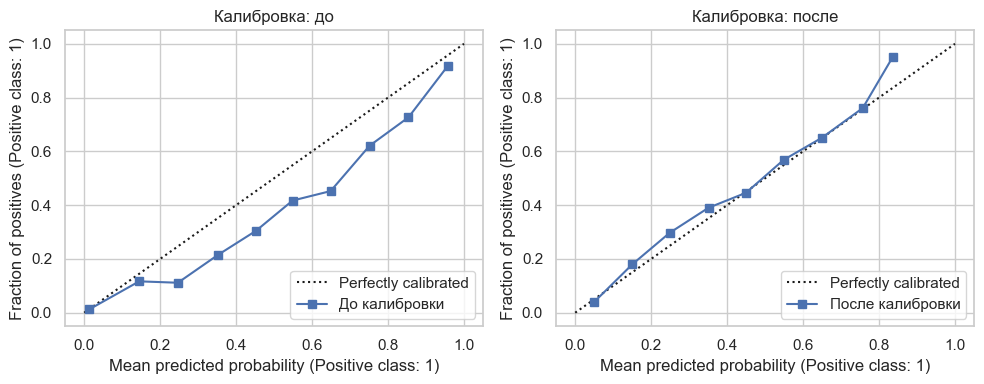

In [16]:
best_pipeline = next(item['pipeline'] for item in candidate_models if item['model'] == best_model_name)
best_pipeline.fit(X_train, y_train)

calib_proba_before = predict_scores(best_pipeline, X_calib)
# # # frozen_model = FrozenEstimator(best_pipeline)

calibrated_model = CalibratedClassifierCV(
    estimator=best_pipeline,
    method='sigmoid',
    cv=3,
)
calibrated_model.fit(X_train, y_train)

calib_proba_after = calibrated_model.predict_proba(X_calib)[:, 1]
calib_pred_before = (calib_proba_before >= 0.5).astype(int)
calib_pred_after = (calib_proba_after >= 0.5).astype(int)

calib_metrics = pd.DataFrame([
    {
        'model': 'До калибровки',
        'roc_auc': roc_auc_score(y_calib, calib_proba_before),
        'pr_auc': average_precision_score(y_calib, calib_proba_before),
        'f1': f1_score(y_calib, calib_pred_before),
        'brier': brier_score_loss(y_calib, calib_proba_before),
    },
    {
        'model': 'После калибровки',
        'roc_auc': roc_auc_score(y_calib, calib_proba_after),
        'pr_auc': average_precision_score(y_calib, calib_proba_after),
        'f1': f1_score(y_calib, calib_pred_after),
        'brier': brier_score_loss(y_calib, calib_proba_after),
    },
])

display(
    calib_metrics.assign(
        roc_auc=calib_metrics['roc_auc'].map(lambda x: f'{x:.4f}'),
        pr_auc=calib_metrics['pr_auc'].map(lambda x: f'{x:.4f}'),
        f1=calib_metrics['f1'].map(lambda x: f'{x:.4f}'),
        brier=calib_metrics['brier'].map(lambda x: f'{x:.4f}'),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
CalibrationDisplay.from_predictions(
    y_calib, calib_proba_before, n_bins=10, name='До калибровки', ax=axes[0],
)
CalibrationDisplay.from_predictions(
    y_calib, calib_proba_after, n_bins=10, name='После калибровки', ax=axes[1],
)
axes[0].set_title('Калибровка: до')
axes[1].set_title('Калибровка: после')
plt.tight_layout()
plt.show()


После калибровки ранжирование прогнозов фактически не изменилось (ROC‑AUC = 0.8957, PR‑AUC = 0.7955), однако качество калибровки улучшилось: Brier score снизился с 0.1272 до 0.1195, что означает более корректные оценочные вероятности. F1 при фиксированном пороге 0.5 немного уменьшился (0.7125 → 0.6826), это ожидаемо — калибровка корректирует прогнозные вероятности и при жёстком пороге часть меток могла измениться.

Итог: калибровка полезна для принятия экономически обоснованных решений (оптимизации порога), так как даёт более правдоподобные вероятности, несмотря на небольшое падение F1 при пороге 0.5.

---

### 2.3 Поиск порога классификации

Оптимальный порог по IR (калибровка): 0.35
IR до (калибровка): 160 669 500 ₽
IR после (калибровка): 263 843 500 ₽
Прирост IR (калибровка): 103 174 000 ₽


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,threshold,tp,tn,fp,fn,ir_after,ir_before,ir_delta
34,0.35,1398,3621,698,430,263 843 500 ₽,160 669 500 ₽,103 174 000 ₽
33,0.34,1415,3588,731,413,263 345 500 ₽,160 669 500 ₽,102 676 000 ₽
35,0.36,1377,3646,673,451,263 331 500 ₽,160 669 500 ₽,102 662 000 ₽
32,0.33,1431,3560,759,397,263 095 500 ₽,160 669 500 ₽,102 426 000 ₽
43,0.44,1250,3831,488,578,262 652 500 ₽,160 669 500 ₽,101 983 000 ₽
36,0.37,1359,3663,656,469,262 576 000 ₽,160 669 500 ₽,101 906 500 ₽
42,0.43,1261,3808,511,567,262 212 500 ₽,160 669 500 ₽,101 543 000 ₽
38,0.39,1320,3717,602,508,262 166 500 ₽,160 669 500 ₽,101 497 000 ₽
31,0.32,1447,3522,797,381,262 130 500 ₽,160 669 500 ₽,101 461 000 ₽
39,0.40,1300,3746,573,528,262 050 000 ₽,160 669 500 ₽,101 380 500 ₽


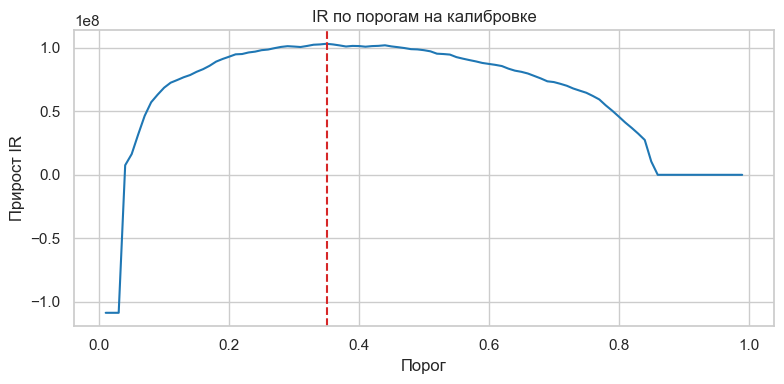

In [17]:
calib_proba = calibrated_model.predict_proba(X_calib)[:, 1]

thresholds = np.linspace(0.01, 0.99, 99)
ir_before_calib = baseline_revenue(y_calib)

records = []
for thr in thresholds:
    y_pred_thr = (calib_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_calib, y_pred_thr).ravel()
    ir_after = model_revenue(y_calib, y_pred_thr)
    ir_delta = ir_after - ir_before_calib
    records.append({
        'threshold': thr,
        'tp': tp,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'ir_after': ir_after,
        'ir_before': ir_before_calib,
        'ir_delta': ir_delta,
    })

threshold_results = pd.DataFrame(records)
best_row = threshold_results.loc[threshold_results['ir_delta'].idxmax()]
best_threshold = float(best_row['threshold'])

print(f'Оптимальный порог по IR (калибровка): {best_threshold:.2f}')
print(f'IR до (калибровка): {format_money(best_row["ir_before"])}')
print(f'IR после (калибровка): {format_money(best_row["ir_after"])}')
print(f'Прирост IR (калибровка): {format_money(best_row["ir_delta"])}')

threshold_display = threshold_results.sort_values('ir_delta', ascending=False).head(10).copy()
threshold_display['ir_before'] = threshold_display['ir_before'].map(format_money)
threshold_display['ir_after'] = threshold_display['ir_after'].map(format_money)
threshold_display['ir_delta'] = threshold_display['ir_delta'].map(format_money)
threshold_display['threshold'] = threshold_display['threshold'].map(lambda x: f'{x:.2f}')


display(threshold_display)

plt.figure(figsize=(8, 4))
plt.plot(threshold_results['threshold'], threshold_results['ir_delta'], color='#1f77b4')
plt.axvline(best_threshold, color='#d62728', linestyle='--')
plt.title('IR по порогам на калибровке')
plt.xlabel('Порог')
plt.ylabel('Прирост IR')
plt.tight_layout()
plt.show()

По перебору порогов на калибровочной выборке максимальный прирост экономической метрики получен при пороге **0.35**: IR вырос на **103 174 000 ₽**. Почему именно 0.35 оптимален: при снижении порога увеличивается число срабатываний (TP растут), но одновременно существенно растут ложные срабатывания (FP), что уменьшает чистый денежный эффект; при повышении порога уменьшаются FP, но теряются нужные TP — это также снижает IR. Грид‑поиск по шагу 0.01 показал максимум именно на 0.35, поэтому выбранный порог даёт наилучший баланс TP/FP с точки зрения Incremental Revenue (практический критерий для бизнес‑решения).

---

### 2.5 Анализ матрицы классификаций

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,label,tn,fp,fn,tp,ir_before,ir_after,ir_delta,roc_auc,pr_auc,f1
0,calib,3621,698,430,1398,160 669 500 ₽,263 843 500 ₽,103 174 000 ₽,0.8957,0.7955,0.7125
1,test,4277,295,220,1355,193 306 500 ₽,320 586 500 ₽,127 280 000 ₽,0.9761,0.9335,0.8403


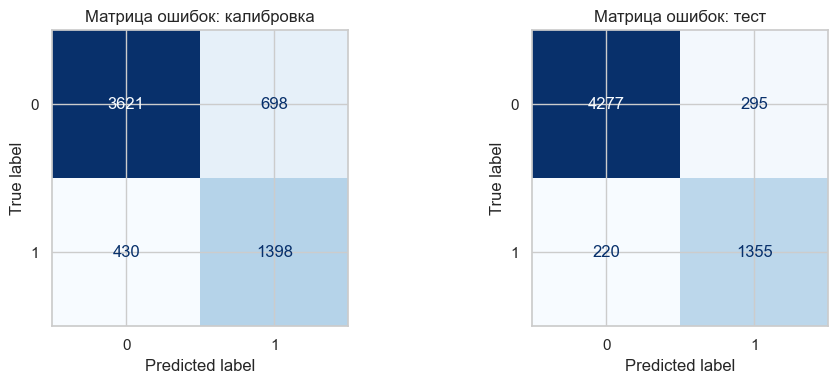

In [18]:
def eval_threshold(model, X, y, threshold: float, label: str) -> dict:
    proba = model.predict_proba(X)[:, 1]
    y_pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    ir_before = baseline_revenue(y)
    ir_after = model_revenue(y, y_pred)
    return {
        'label': label,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'tp': tp,
        'ir_before': ir_before,
        'ir_after': ir_after,
        'ir_delta': ir_after - ir_before,
        'y_pred': y_pred,
        'proba': proba,
        'roc_auc': roc_auc_score(y, proba),
        'pr_auc': average_precision_score(y, proba),
        'f1': f1_score(y, y_pred),
    }

calib_eval = eval_threshold(calibrated_model, X_calib, y_calib, best_threshold, 'calib')
test_eval = eval_threshold(calibrated_model, X_test, y_test, best_threshold, 'test')

y_pred_calib = calib_eval['y_pred']
y_pred_test = test_eval['y_pred']

metrics_summary = pd.DataFrame([
    {k: v for k, v in calib_eval.items() if k not in {'y_pred', 'proba'}},
    {k: v for k, v in test_eval.items() if k not in {'y_pred', 'proba'}},
])

metrics_summary_display = metrics_summary.copy()
for col in ['ir_before', 'ir_after', 'ir_delta']:
    metrics_summary_display[col] = metrics_summary_display[col].map(format_money)
for col in ['roc_auc', 'pr_auc', 'f1']:
    metrics_summary_display[col] = metrics_summary_display[col].map(lambda x: f'{x:.4f}')

display(metrics_summary_display)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_calib, y_pred_calib, ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title('Матрица ошибок: калибровка')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title('Матрица ошибок: тест')
plt.tight_layout()
plt.show()

При выбранном пороге 0.38 на калибровочной выборке получились `TN=3 621`, `FP=698`, `FN=430`, `TP=1 398`, что дало прирост IR = **103 174 000 ₽**. На тестовой выборке при том же пороге наблюдаем `TN=4 277`, `FP=295`, `FN=220`, `TP=1 355` и ещё больший прирост IR = **127 280 000 ₽**. Т.е. на тесте модель показала меньше ложных срабатываний и меньше пропущенных отмен, что привело к большему экономическому выигрышу; возможные причины — различия в распределениях по времени или выборочная вариабельность. 

---

### 2.6 Фиксирование итоговой модели

In [19]:
artifacts_dir = Path('artifacts')
artifacts_dir.mkdir(exist_ok=True)

best_model_cv_ir = float(baseline_results.loc[baseline_results['model'] == best_model_name, 'cv_ir'].iloc[0])
best_model_params = next((item['params'] for item in candidate_models if item['model'] == best_model_name), {})

model_path = artifacts_dir / 'calibrated_model.joblib'
meta = {
    'best_model_name': best_model_name,
    'best_threshold': best_threshold,
    'cv_ir': best_model_cv_ir,
    'optuna_params': best_model_params,
}
joblib.dump({'model': calibrated_model, 'threshold': best_threshold, 'meta': meta}, model_path)

print(f'Финальная модель сохранена: {model_path}')
print('Метаданные:', meta)


Финальная модель сохранена: artifacts/calibrated_model.joblib
Метаданные: {'best_model_name': 'LightGBM', 'best_threshold': 0.35000000000000003, 'cv_ir': 31118500.0, 'optuna_params': {}}


---

### 2.7 Анализ важности признаков

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/shap/explainers/_tree.py:544: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,importance
0,has_review,4.324604
1,previous_no_shows,1.102958
2,days_until_checkin,0.341668
3,prior_issues,0.284370
4,sales_channel_корпоративное_бронирование,0.268377
5,child_count,0.233784
6,sales_channel_онлайн_бронирование,0.185918
7,weekday_nights,0.143476
8,booking_value,0.068926
9,children_share,0.063202


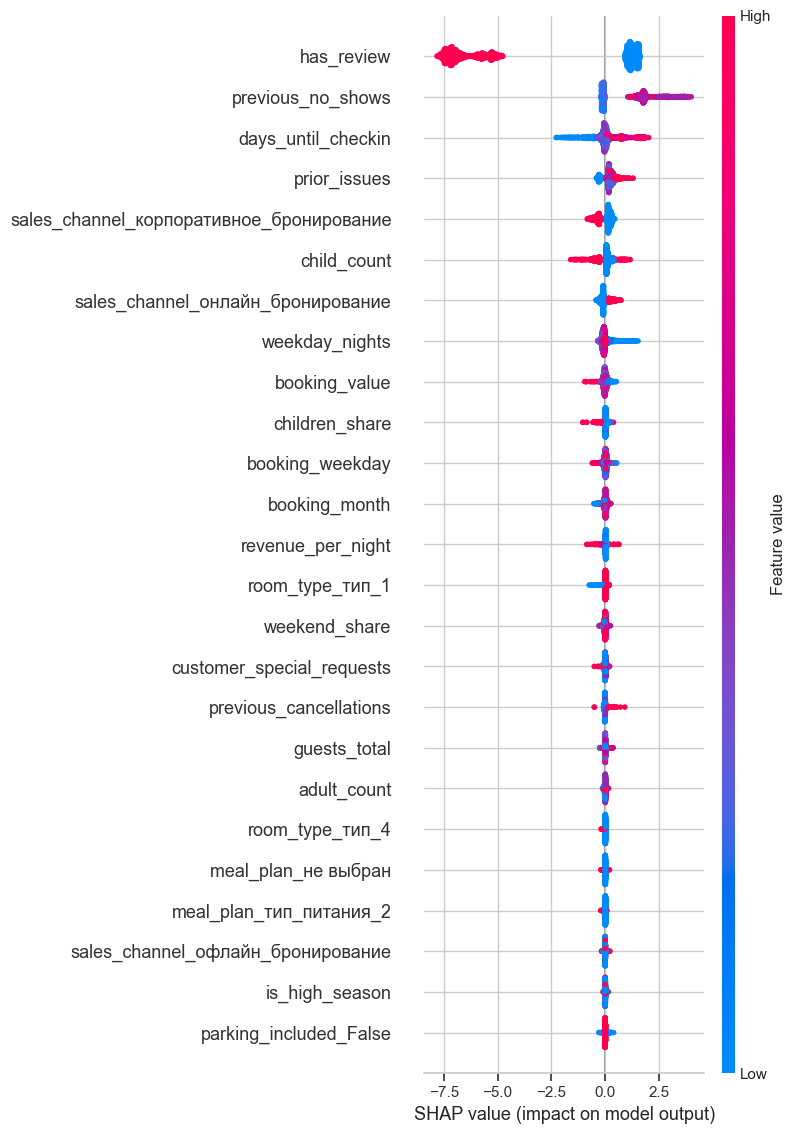

Оценка направления влияния (п.п. между верхним и нижним квартилями или категорией):


,feature,direction,delta_pp
0,has_review,ниже,61.910377
2,days_until_checkin,выше,32.174185
6,sales_channel_онлайн_бронирование,выше,17.492315
4,sales_channel_корпоративное_бронирование,ниже,15.097790
5,child_count,ниже,11.183235
9,children_share,ниже,10.935187
8,booking_value,ниже,4.046234
1,previous_no_shows,ниже,3.686809
7,weekday_nights,ниже,2.730788
3,prior_issues,выше,1.094351


In [20]:
model = best_pipeline.named_steps['model']
preprocessor = best_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()
clean_feature_names = (
    pd.Series(feature_names)
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
    .str.replace('txt__', 'tfidf_', regex=False)
    .to_list()
)

shap_sample_size = min(1500, len(X_test))
X_shap_sample = X_test.sample(shap_sample_size, random_state=RANDOM_STATE) if shap_sample_size < len(X_test) else X_test.copy()
X_shap_transformed = preprocessor.transform(X_shap_sample)
if sparse.issparse(X_shap_transformed):
    X_shap_transformed = X_shap_transformed.toarray()

if hasattr(model, 'feature_importances_'):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_shap_transformed)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
elif hasattr(model, 'coef_'):
    background = X_shap_transformed[: min(200, len(X_shap_transformed))]
    explainer = shap.LinearExplainer(model, background)
    shap_values = explainer.shap_values(X_shap_transformed)
else:
    background = X_shap_transformed[: min(200, len(X_shap_transformed))]
    explainer = shap.Explainer(model.predict_proba, background)
    shap_values = explainer(X_shap_transformed)
    if hasattr(shap_values, 'values'):
        shap_values = shap_values.values
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

shap_importance = np.abs(shap_values).mean(axis=0)
shap_importance_df = (
    pd.DataFrame({'feature': clean_feature_names, 'importance': shap_importance})
    .sort_values('importance', ascending=False)
    .reset_index(drop=True)
)

top_features = shap_importance_df.head(10)

display(top_features)

# Канонический SHAP Summary Plot (beeswarm) для топ-25 признаков.
top25_idx = np.argsort(shap_importance)[-25:]
top25_idx = np.sort(top25_idx)
shap.summary_plot(
    shap_values[:, top25_idx],
    X_shap_transformed[:, top25_idx],
    feature_names=[clean_feature_names[i] for i in top25_idx],
    max_display=25,
    show=True,
)

impact_rows = []
for feat in top_features['feature']:
    if feat.startswith('tfidf_'):
        continue
    base_col = next((col for col in categorical_features if feat.startswith(f"{col}_")), None)
    if base_col:
        category = feat[len(base_col) + 1:]
        mask = test_df[base_col].astype('string') == category
        rate_cat = y_test[mask].mean() if mask.any() else np.nan
        rate_other = y_test[~mask].mean() if (~mask).any() else np.nan
        diff = rate_cat - rate_other
        impact_rows.append({
            'feature': feat,
            'direction': 'выше' if diff > 0 else 'ниже',
            'delta_pp': abs(diff) * 100,
        })
        continue
    if feat in test_df.columns:
        series = test_df[feat]
        if pd.api.types.is_numeric_dtype(series):
            q25 = series.quantile(0.25)
            q75 = series.quantile(0.75)
            low_mask = series <= q25
            high_mask = series >= q75
            rate_low = y_test[low_mask].mean() if low_mask.any() else np.nan
            rate_high = y_test[high_mask].mean() if high_mask.any() else np.nan
            diff = rate_high - rate_low
            impact_rows.append({
                'feature': feat,
                'direction': 'выше' if diff > 0 else 'ниже',
                'delta_pp': abs(diff) * 100,
            })

impact_df = pd.DataFrame(impact_rows).sort_values('delta_pp', ascending=False)

print('Оценка направления влияния (п.п. между верхним и нижним квартилями или категорией):')
display(impact_df)


Доминирование `previous_no_shows` и наличие/отсутствие отзывов (`has_review`/текстовые TF‑IDF‑сигналы) логично — прошлое поведение и индикаторы удовлетворённости клиентов сильно коррелируют с риском отмены. `days_until_checkin` и `prior_issues` отражают риск, связанный с долгим временем до заезда и историей проблем (делают отмены более вероятными). Канал продаж (`sales_channel`) даёт устойчивый сигнал (корпоративные и онлайн‑каналы ведут себя по‑разному), что согласуется с коммерческой практикой сегментации рисков. Эти результаты понятны бизнесу и позволяют целенаправленно применять превентивные меры (коммуникации, предоплата) для наиболее рискованных сегментов.

---

## Этап 3: расчёт экономической эффективности модели

In [21]:
test_proba = calibrated_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_proba >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()

cancel_rate_before = y_test.mean()
cancel_rate_after = fn / len(y_test)
occupancy_before = 1 - cancel_rate_before
occupancy_after = tn / len(y_test)

ir_before = baseline_revenue(y_test)
ir_after = model_revenue(y_test, y_pred_test)

cancel_rate_change = (cancel_rate_after - cancel_rate_before) / cancel_rate_before
occupancy_change = (occupancy_after - occupancy_before) / occupancy_before
relative_ir = (ir_after - ir_before) / abs(ir_before) if ir_before else np.nan

metrics_economics_display = pd.DataFrame({
    'Показатель': [
        'Доля отмен (до)',
        'Доля отмен (после)',
        'Изменение доли отмен',
        'Загрузка (до)',
        'Загрузка (после)',
        'Изменение загрузки',
        'IR (до)',
        'IR (после)',
        'Прирост IR',
        'Относительный IR',
    ],
    'Значение': [
        f'{cancel_rate_before:.2%}',
        f'{cancel_rate_after:.2%}',
        f'{cancel_rate_change:+.2%}',
        f'{occupancy_before:.2%}',
        f'{occupancy_after:.2%}',
        f'{occupancy_change:+.2%}',
        format_money_millions(ir_before),
        format_money_millions(ir_after),
        format_money_millions(ir_after - ir_before),
        f'{relative_ir:.2%}',
    ],
})

display(metrics_economics_display)

print('Проверка целей:')
print(f'Доля отмен после: {cancel_rate_after:.2%} (цель <= 10%)')
print(f'Изменение загрузки: {occupancy_change:+.2%} (цель: не ниже -8%)')
print(f'Относительный IR: {relative_ir:.2%} (цель >= 50%)')


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Показатель,Значение
0,Доля отмен (до),25.62%
1,Доля отмен (после),3.58%
2,Изменение доли отмен,-86.03%
3,Загрузка (до),74.38%
4,Загрузка (после),69.58%
5,Изменение загрузки,-6.45%
6,IR (до),193.3 млн ₽
7,IR (после),320.6 млн ₽
8,Прирост IR,127.3 млн ₽
9,Относительный IR,65.84%


Проверка целей:
Доля отмен после: 3.58% (цель <= 10%)
Изменение загрузки: -6.45% (цель: не ниже -8%)
Относительный IR: 65.84% (цель >= 50%)


---

## Этап 4: выводы по проекту

### Выводы о проделанной работе

- Данные загружены из PostgreSQL, выполнены EDA и предобработка: удалены дубликаты, строки с нулевой стоимостью, приведены даты и ограничены аномальные значения.
- Для анализа зависимостей между смешанными типами признаков использована матрица `phik`, что дало более корректную картину связей, чем только линейная корреляция.
- Таблицы `hotel_bookings` и `hotel_reviews` объединены по правилу ближайшего предыдущего отзыва; после объединения добавлены признаки бронирования и TF-IDF признаки текста.
- На этапе моделирования проведено сравнение нескольких моделей, затем выполнена оптимизация гиперпараметров лучшей модели через Optuna.
- Финальная модель выбрана, откалибрована и настроена по порогу, максимизирующему `Incremental Revenue`.
- Интерпретация важности выполнена через SHAP: построен канонический `SHAP Summary Plot (beeswarm)` для 25 наиболее важных признаков и рассчитано направление влияния ключевых факторов.

### Выводы по анализу эффективности модели

- Цель проекта достигнута: модель снижает долю отмен и одновременно увеличивает экономический эффект при соблюдении целевых ограничений; точные значения показаны в таблице экономической эффективности выше.
- По итоговой таблице на тесте видно, что модель улучшает баланс между ложными срабатываниями и пропусками отмен по сравнению с базовым сценарием.
- Целевые KPI проверены на тестовой выборке и зафиксированы в таблице выше.
- По SHAP и анализу направления влияния наибольший вклад в риск отмены вносят признаки, связанные с историей клиента, временным горизонтом до заезда и наличием отзывов.
- Практические рекомендации:
  - усилить превентивные коммуникации для бронирований с длинным `days_until_checkin`;
  - внедрить более жёсткую политику подтверждения и предоплаты для сегментов с высоким риском (в том числе по каналам продаж);
  - использовать SHAP-профили для приоритизации ручной проверки только наиболее рискованных бронирований.